In [2]:
import pandas as pd
import openpyxl
import numpy as np
import matplotlib.pyplot as plt
import random
import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
warnings.filterwarnings("ignore")
from IPython.display import display
import ipywidgets as widgets
from IPython.display import display, clear_output

Definicje:
1) $\textbf{support}$ - jak często dany produkt pojawiał się w transakcjach
$$ \text{support}(A) = \frac{\text{ilość transakcji zawierające A}}{\text{ilość wszystkich transakcji}} $$
2) $\textbf{confidence}$ - prawdopodobieństwo, że transakcja zawierająca produkt A zawiera również produkt B
$$ \text{confidence}(A \Rightarrow B) = \frac{\text{ilość transakcji zawierających } A \text{ i } B}{\text{ilość transakcji zawierających } A} $$
3) $\textbf{lift}$ - siła związku między produktami A i B. Porównuje, jak często produkty A i B występują razem w stosunku do tego, jak często można by oczekiwać ich wspólnego wystąpienia
$$ \text{lift}(A \Rightarrow B) = \frac{\text{confidence}(A \Rightarrow B)}{\text{support}(B)} $$
- **lift > 1**: Produkty $A$ i $B$ mają pozytywną korelację – występują razem częściej, niż by to wynikało z przypadku.
- **lift = 1**: Produkty $A$ i $B$ są niezależne.
- **lift < 1**: Produkty $A$ i $B$ występują razem rzadziej, niż by to wynikało z przypadku.


In [3]:
dane = pd.read_excel('http://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx')
display(dane.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Najpierw sprawdzimy czy w danych znajdują się wartości NaN

In [4]:
ile_NaN = dane.isna().sum()

print("\nLiczba wartosci NaN w kolumnach:")
print("")
print(ile_NaN)


Liczba wartosci NaN w kolumnach:

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


Widzimy że wartośći NaN znajdują się w kolumnie Description i CustomerID wiec je usuniemy

In [5]:
dane.dropna(axis = 0, how = "any", inplace = True)

In [6]:
ile_NaN = dane.isna().sum()

print("\nLiczba wartosci NaN w kolumnach:")
print("")
print(ile_NaN)


Liczba wartosci NaN w kolumnach:

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


Wykonamy kilka niezbędnych przekształceń danych

In [7]:
# Będziemy rozważać dane z roku 2011
dane = dane[dane['InvoiceDate'].astype(str).str.contains('2011')].copy()
# Zmieniamy typ danych w kolumnie 'StockCode' na string
dane['StockCode'] = dane['StockCode'].astype(str)
# Tworzymy nową kolumnę 'length', która zawiera długość wartości w kolumnie 'StockCode'
dane['length'] = dane['StockCode'].str.len()
# Wybieramy tylko te wiersze, gdzie długość kodu w 'StockCode' mieści się w przedziale 5-7 znaków
dane = dane[dane['StockCode'].str.len().between(5, 7)]
# Zmieniamy typ danych w kolumnie 'InvoiceNo' na string
dane['InvoiceNo'] = dane['InvoiceNo'].astype(str)
# Usuwamy wiersze, gdzie 'InvoiceNo' zawiera znak 'C', które oznacza anulowanie transakcji
dane = dane[~dane['InvoiceNo'].str.contains('C')]
# Wybieramy wiersze, gdzie opisy w kolumnie 'Description' są zapisane małymi literami
dane = dane[~dane['Description'].str.islower()]
# Usuwamy wiersze z ujemnymi wartościami w kolumnie 'Quantity'
dane = dane[dane['Quantity'] >= 0]
# Zachowujemy tylko te wiersze, które mają zduplikowaną wartość w kolumnie 'InvoiceNo'
dane = dane[dane.duplicated(subset='InvoiceNo', keep=False)]

Narysujemy poglądowy wykres przedstawiający czestotliwość występowania 10 losowych produktów w naszych danych

In [8]:
value_counts = dane['Description'].value_counts()
random.seed(42)
random_samples = random.sample(list(value_counts.index), 10)
plot_data = value_counts.loc[random_samples]

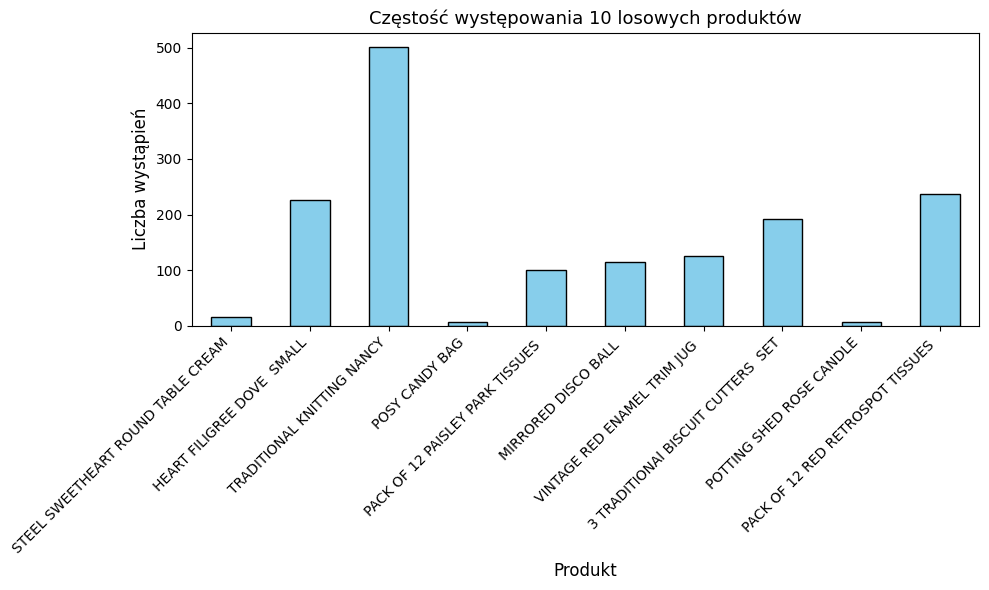

In [9]:
plt.figure(figsize=(10, 6))
plot_data.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Częstość występowania 10 losowych produktów', fontsize=13)
plt.xlabel('Produkt', fontsize=12)
plt.ylabel('Liczba wystąpień', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

# Pierwsza metoda - Apriori

## Przykład użycia Apriori

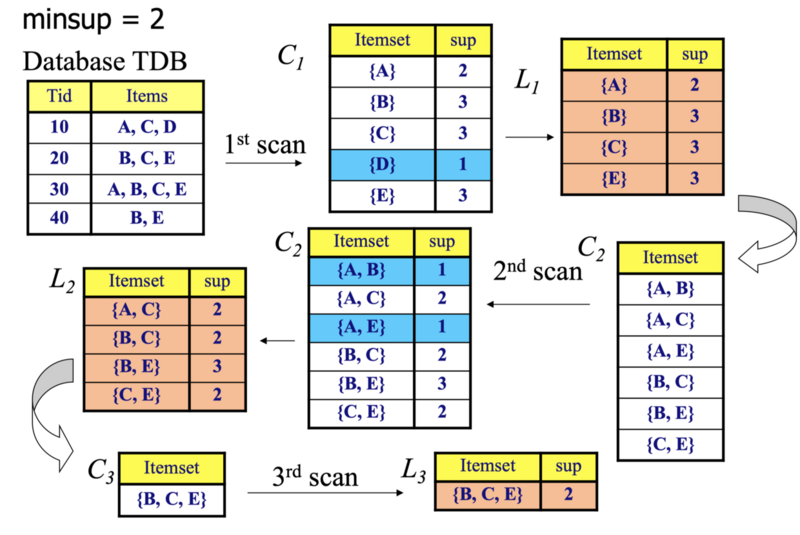

### Jak to działa?

Apriori szuka **często kupowanych razem zestawów produktów** krok po kroku, od pojedynczych produktów do coraz większych zestawów. Opiera się na jednej prostej zasadzie: *jeśli zestaw jest rzadki, to każdy zestaw, który go zawiera, też będzie rzadki* – więc nie ma sensu go dalej sprawdzać.

Na przykładzie z rysunku (4 transakcje, minimalne wsparcie = 2):

1. **1. skan:** zliczamy, w ilu transakcjach występuje każdy produkt osobno. Produkt D pojawia się tylko raz (mniej niż 2), więc odpada.
2. **2. skan:** z pozostałych produktów (A, B, C, E) tworzymy pary i znów je zliczamy. Pary {A,B} i {A,E} występują tylko raz, więc odpadają. Zostają {A,C}, {B,C}, {B,E} i {C,E}.
3. **3. skan:** z „ocalałych" par tworzymy trójki. Zestaw {A,C,E} nawet nie jest sprawdzany, bo zawiera rzadką parę {A,E}. Zostaje tylko {B,C,E} (wsparcie 2).
4. Kończymy, gdy nie da się zbudować kolejnego, większego zestawu. Dopiero z takich częstych zestawów liczymy reguły (confidence, lift).

**Zaleta:** prosty i łatwy do zrozumienia. **Wada:** każdy poziom to kolejny przebieg po całych danych, więc przy wielu produktach działa wolno. W naszym projekcie szukamy zestawów występujących w co najmniej 5% transakcji (`min_support = 0.05`).

Tworzymy koszyk transakcji dla Niemiec, który pokazuje, jakie produkty znajdowały się w poszczególnych transakcjach

In [10]:
koszyk = (dane[dane['Country']=="Germany"]
          .groupby(['InvoiceNo', 'Description'])
          .size()
          .unstack()
          .fillna(0)
          .reset_index()
          .set_index('InvoiceNo'))
display(koszyk)

Description,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
540410,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
540414,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
540458,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
540480,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
540553,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581266,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
581494,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
581570,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Sprawdzamy czy w koszyku znajdują się produkty które występują więcej niż 1 raz

In [11]:
if (koszyk > 1).any().any():
    print("Zawiera wartość większą od 1.")
else:
    print("Nie zawiera wartości większych od 1.")

Zawiera wartość większą od 1.


Tworzymy funkcje która zamienia wartości na 0-1

In [12]:
def binarne(x):
    if x>=1:
        return 1
    else:
        return 0

Używamy jej na naszym koszyku

In [13]:
koszykv2 = koszyk.apply(lambda kolumna: kolumna.map(binarne))

Sprawdzamy czy funkcja dobrze zadziałała

In [14]:
if (koszykv2 > 1).any().any():
    print("Zawiera wartość większą od 1.")
else:
    print("Nie zawiera wartości większych od 1.")

Nie zawiera wartości większych od 1.


In [17]:
czestotliwosc = apriori(koszykv2, min_support = 0.05, use_colnames = True)
display(czestotliwosc)

rules = association_rules(czestotliwosc, metric="support", min_threshold=0.1)
rules = rules.sort_values(by = "support", ascending = False)
display(rules)


czestotliwosc_widzet = apriori(koszykv2, min_support=0.02, use_colnames=True, max_len=3)

def co_jeszcze(produkt,metric,min_prog):
    rules = association_rules(czestotliwosc_widzet, metric = metric, min_threshold = min_prog)
    rules = rules.sort_values(by = metric, ascending = False)
    filtered_rules = rules[rules['antecedents'].apply(lambda x: produkt in x)]
    return filtered_rules.head(3)

def co_jeszcze_gui():
    wszystkie_reguly = association_rules(czestotliwosc_widzet, metric="support", min_threshold=0)
    available_products = sorted({p for zbior in wszystkie_reguly['antecedents'] for p in zbior})

    product_select = widgets.Dropdown(options=available_products, description='Produkt:', style={'description_width': 'initial'}, layout=widgets.Layout(width='50%'))
    metric_select = widgets.Dropdown(options=['support', 'confidence', 'lift'], value='support', description='Metryka:', style={'description_width': 'initial'})
    threshold_input = widgets.FloatText(value=0.1, description='Min. próg:', style={'description_width': 'initial'})
    button = widgets.Button(description='OK', button_style='primary')
    output = widgets.Output()

    def on_button_clicked(b):
        with output:
            clear_output()
            try:
                min_prog = float(threshold_input.value)
            except ValueError:
                print("Błąd: Minimalny próg musi być liczbą!")
                return

            result = co_jeszcze(product_select.value, metric_select.value, min_prog)

            if result.empty:
                print("Brak reguł spełniających podane kryteria.")
            else:
                kolumny = ['antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift', 'leverage']
                print(f"\nWyniki dla produktu: {product_select.value}")
                display(result[[k for k in kolumny if k in result.columns]])

    button.on_click(on_button_clicked)
    display(widgets.VBox([product_select, metric_select, threshold_input, button, output]))

co_jeszcze_gui()

,support,itemsets
0,0.1050,(6 RIBBONS RUSTIC CHARM)
1,0.0750,(ALARM CLOCK BAKELIKE PINK)
2,0.0500,(ALARM CLOCK BAKELIKE RED )
3,0.0500,(BAKING SET 9 PIECE RETROSPOT )
4,0.0525,(BLUE HARMONICA IN BOX )
...,...,...
81,0.0500,"(ROUND SNACK BOXES SET OF 4 FRUITS , WOODLAND CHARLOTTE BAG)"
82,0.0775,"(ROUND SNACK BOXES SET OF4 WOODLAND , SPACEBOY LUNCH BOX )"
83,0.0500,"(STRAWBERRY LUNCH BOX WITH CUTLERY, ROUND SNACK BOXES SET OF4 WOODLAND )"
84,0.0700,"(ROUND SNACK BOXES SET OF4 WOODLAND , WOODLAND CHARLOTTE BAG)"


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(ROUND SNACK BOXES SET OF 4 FRUITS ),(ROUND SNACK BOXES SET OF4 WOODLAND ),0.17,0.26,0.14,0.823529,3.167421,1.0,0.0958,4.193333,0.824441,0.482759,0.761526,0.680995
1,(ROUND SNACK BOXES SET OF4 WOODLAND ),(ROUND SNACK BOXES SET OF 4 FRUITS ),0.26,0.17,0.14,0.538462,3.167421,1.0,0.0958,1.798333,0.924710,0.482759,0.443930,0.680995


| **Metryka**  | **Zalety**                                                                                                                                                              | **Wady**                                                                                                                                                                                                                                                                                          |
|---------------|------------------------------------------------------------------------------------------------------------------------------------------------------------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Support**   |  Prosta interpretacja.                                                                                                                                                 | Niski support może powodować odrzucenie rzadkich, ale cennych reguł. <br>  Wysoki support niekoniecznie oznacza dużą wartość dla analizy.                                                                                                                                                     |
| **Confidence**|  Daje informację o kierunku relacji między produktami. <br>  Prosta interpretacja jako prawdopodobieństwo warunkowe.                                                  |  Może być myląca przy produktach o wysokim support. <br>  Nie bierze pod uwagę ogólnej częstotliwości produktu B. <br> Wartość zależy od częstotliwości poprzednika, co może zaniżać metrykę w przypadku rzeczywistego związku między produktami.                                          |
| **Lift**      |  Umożliwia eliminację fałszywie pozytywnych reguł z wysokim confidence, które mogą wynikać z popularności produktu B, a nie z rzeczywistego związku z produktem A. <br>  Wskazuje, jak bardzo wystąpienie jednego produktu zwiększa (lub zmniejsza) prawdopodobieństwo wystąpienia drugiego. |  Trudniejszy do interpretacji niż support i confidence. <br>  Wymaga obliczenia wszystkich wcześniejszych metryk, co może być bardziej czasochłonne przy dużych zbiorach danych.                                                                         |



In [16]:
import plotly.express as px

# Konwersja kolumn 'antecedents' i 'consequents' do stringów
rules['antecedents'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

fig = px.scatter(
    rules,
    x='support',
    y='confidence',
    color='lift',
    size='lift',
    hover_data=['antecedents', 'consequents'],
    title='2D Plot of Support, Confidence, and Lift',
    labels={'support': 'Support', 'confidence': 'Confidence'}
)

fig.show()


# Druga metoda - ECLAT

In [ ]:
from pyECLAT import ECLAT

## Przykład użycia ECLAT

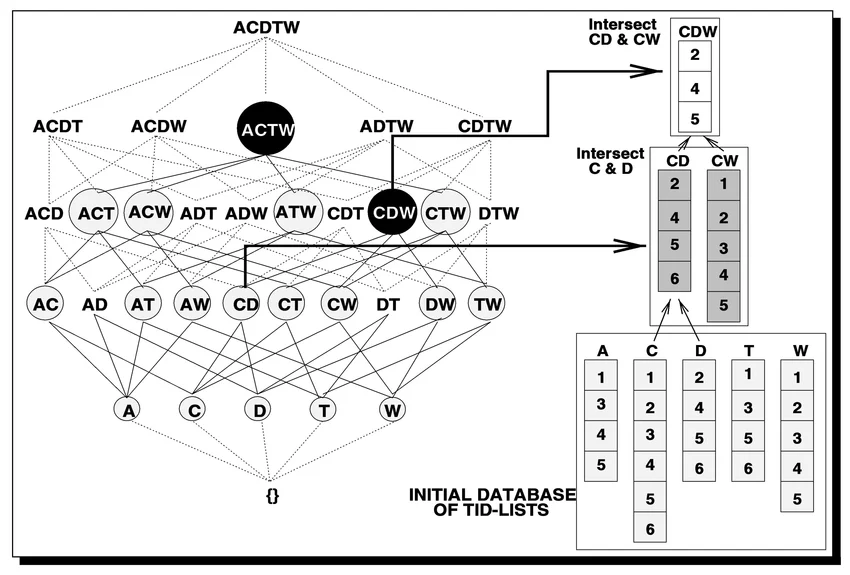

### Jak to działa?

ECLAT robi to samo co Apriori (szuka często kupowanych zestawów), ale **odwraca sposób zapisu danych**. Zamiast „transakcja → lista produktów" zapisuje dla każdego produktu **listę numerów transakcji, w których się pojawił** (tabela *Initial database of TID-lists* na rysunku).

Wsparcie zestawu produktów liczymy wtedy jako **część wspólną tych list**:

1. Produkt C występuje w transakcjach {1, 2, 3, 4, 5, 6}, a produkt D w {2, 4, 5, 6}.
2. Część wspólna daje transakcje, w których były oba: C ∩ D = {2, 4, 5, 6}, czyli zestaw {C, D} ma wsparcie 4.
3. Podobnie {C, W} występuje w {1, 2, 3, 4, 5}. Gdy przetniemy {C, D} z {C, W}, dostaniemy {2, 4, 5}, czyli zestaw {C, D, W} ma wsparcie 3.
4. Zestaw jest „częsty", jeśli ma wsparcie nie mniejsze niż ustalony próg. Przeszukujemy kolejne kombinacje w głąb, aż lista wspólna będzie za krótka.

**Zaleta:** zamiast za każdym razem skanować całą bazę, wystarczy przecinać krótkie listy. **Wada:** przy bardzo dużych danych same listy numerów transakcji mogą zajmować dużo pamięci. W kodzie poniżej `min_support` to próg wsparcia, a `min_combination` i `max_combination` ograniczają rozmiar szukanych zestawów (u nas od 2 do 3 produktów).

Nie będziemy ponownie ładować danych i powtarzać identycznych operacji przekształceń żeby usprawić analizę

In [ ]:
display(dane.iloc[:, :-1])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
42481,539993,22386,JUMBO BAG PINK POLKADOT,10,04.01.2011 10:00,"1,95",13313.0,United Kingdom
42482,539993,21499,BLUE POLKADOT WRAP,25,04.01.2011 10:00,"0,42",13313.0,United Kingdom
42483,539993,21498,RED RETROSPOT WRAP,25,04.01.2011 10:00,"0,42",13313.0,United Kingdom
42484,539993,22379,RECYCLING BAG RETROSPOT,5,04.01.2011 10:00,"2,1",13313.0,United Kingdom
42485,539993,20718,RED RETROSPOT SHOPPER BAG,10,04.01.2011 10:00,"1,25",13313.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,09.12.2011 12:50,"0,85",12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,09.12.2011 12:50,"2,1",12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,09.12.2011 12:50,"4,15",12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,09.12.2011 12:50,"4,15",12680.0,France


In [ ]:
transactions_list = dane[dane['Country']=="Germany"].groupby('InvoiceNo')['Description'].apply(list).tolist()
transactions_df = pd.DataFrame(transactions_list)
display(transactions_df)

,0,1,2,3,4,5,6,7,8,9,...,138,139,140,141,142,143,144,145,146,147
0,SET/4 WHITE RETRO STORAGE CUBES,PINK POLKADOT CHILDRENS UMBRELLA,RED RETROSPOT CHILDRENS UMBRELLA,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,RED 3 PIECE RETROSPOT CUTLERY SET,RED TOADSTOOL LED NIGHT LIGHT,TOADSTOOL MONEY BOX,...,None,None,None,None,None,None,None,None,None,None
1,RED RETROSPOT TAPE,STARS GIFT TAPE,RAIN PONCHO RETROSPOT,POLKADOT RAIN HAT,VICTORIAN GLASS HANGING T-LIGHT,RIDGED GLASS POSY VASE,BAKING SET 9 PIECE RETROSPOT,PEG BAG APPLES DESIGN,CLOTHES PEGS RETROSPOT PACK 24,ROUND SNACK BOXES SET OF4 WOODLAND,...,None,None,None,None,None,None,None,None,None,None
2,CHARLOTTE BAG DOLLY GIRL DESIGN,WOODLAND CHARLOTTE BAG,RED RETROSPOT CHARLOTTE BAG,RETROSPOT PARTY BAG + STICKER SET,RED RETROSPOT SHOPPER BAG,RED RETROSPOT PURSE,RED RETROSPOT UMBRELLA,EDWARDIAN PARASOL RED,EDWARDIAN PARASOL BLACK,EDWARDIAN PARASOL NATURAL,...,VINTAGE PAISLEY STATIONERY SET,MINI FUNKY DESIGN TAPES,RED RETROSPOT TAPE,SKULLS TAPE,STARS GIFT TAPE,CAKES AND BOWS GIFT TAPE,FELT EGG COSY LADYBIRD,MAGNETS PACK OF 4 VINTAGE LABELS,MAGNETS PACK OF 4 RETRO PHOTO,TV DINNER TRAY AIR HOSTESS
3,SCOTTIES DESIGN WASHBAG,SAVE THE PLANET COTTON TOTE BAG,WOODLAND DESIGN COTTON TOTE BAG,LOLITA DESIGN COTTON TOTE BAG,SILK PURSE BABUSHKA PINK,SILK PURSE BABUSHKA BLUE,SILK PURSE BABUSHKA RED,RED RETROSPOT MINI CASES,RED RETROSPOT UMBRELLA,CHARLOTTE BAG SUKI DESIGN,...,None,None,None,None,None,None,None,None,None,None
4,EASTER TIN KEEPSAKE,EASTER TIN CHICKS IN GARDEN,PACK OF 6 BIRDY GIFT TAGS,DOORMAT AIRMAIL,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,SET OF 6 RIBBONS PARTY,LETS GO SHOPPING COTTON TOTE BAG,WOODLAND CHARLOTTE BAG,WOODLAND MINI BACKPACK,ELEPHANT BIRTHDAY CARD,GIN & TONIC DIET GREETING CARD,WRAP 50'S CHRISTMAS,WRAP RED APPLES,WRAP WEDDING DAY,WRAP POPPIES DESIGN,...,None,None,None,None,None,None,None,None,None,None
396,RABBIT NIGHT LIGHT,STRAWBERRY LUNCH BOX WITH CUTLERY,"FANCY FONT BIRTHDAY CARD,",CARD CIRCUS PARADE,PLASTERS IN TIN CIRCUS PARADE,ROUND SNACK BOXES SET OF 4 FRUITS,ALARM CLOCK BAKELIKE IVORY,HAND WARMER UNION JACK,ROUND SNACK BOXES SET OF4 WOODLAND,MINI FUNKY DESIGN TAPES,...,None,None,None,None,None,None,None,None,None,None
397,CHRISTMAS CRAFT TREE TOP ANGEL,PINK OWL SOFT TOY,FAWN BLUE HOT WATER BOTTLE,TRADITIONAL PICK UP STICKS GAME,ROUND SNACK BOXES SET OF4 WOODLAND,WOODLAND PARTY BAG + STICKER SET,HAND WARMER BABUSHKA DESIGN,BLUE HARMONICA IN BOX,RETROSPOT TEA SET CERAMIC 11 PC,DOUGHNUT LIP GLOSS,...,None,None,None,None,None,None,None,None,None,None
398,ROUND SNACK BOXES SET OF4 WOODLAND,ROUND SNACK BOXES SET OF 4 FRUITS,JUMBO BAG APPLES,JUMBO BAG PAISLEY PARK,SET OF 4 KNICK KNACK TINS LONDON,SET OF 4 KNICK KNACK TINS LEAF,VICTORIAN SEWING BOX MEDIUM,VICTORIAN SEWING BOX LARGE,PARISIENNE SEWING BOX,6 RIBBONS RUSTIC CHARM,...,None,None,None,None,None,None,None,None,None,None


In [ ]:
eclat = ECLAT(data=transactions_df)
eclat.df_bin

,PIN CUSHION BABUSHKA RED,ANT COPPER LIME BOUDICCA BRACELET,SKULL AND CROSSBONES GARLAND,RED PAPER PARASOL,FLYING PIG WATERING CAN,SMALL DECO JEWELLERY STAND,SET 2 TEA TOWELS I LOVE LONDON,WOODLAND PARTY BAG + STICKER SET,TEA TIME TEA SET IN GIFT BOX,ROCOCO WALL MIRROR WHITE,...,FRENCH BATHROOM SIGN BLUE METAL,MOODY BOY DOOR HANGER,PACK OF 12 STICKY BUNNIES,GREEN POLKADOT BOWL,WOODLAND BUNNIES LOLLY MAKERS,SET 36 COLOUR PENCILS LOVE LONDON,LONDON BUS COFFEE MUG,ENAMEL PINK COFFEE CONTAINER,WOODEN FRAME ANTIQUE WHITE,PAIR PADDED HANGERS PINK CHECK
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
396,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
397,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
398,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
min_support = 8/100
min_combination = 2
max_combination = 3

rule_indices, rule_supports = eclat.fit(min_support=min_support,
                                                 min_combination=min_combination,
                                                 max_combination=max_combination,
                                                 separator=' & ',
                                                 verbose=True)

Combination 2 by 2


136it [00:06, 20.98it/s]


Combination 3 by 3


680it [00:32, 21.17it/s]


In [ ]:
pd.set_option('display.max_colwidth', None)
result = pd.DataFrame(rule_supports.items(),columns=['Item', 'Support'])
result.sort_values(by=['Support'], ascending=False)

,Item,Support
0,ROUND SNACK BOXES SET OF 4 FRUITS & ROUND SNACK BOXES SET OF4 WOODLAND,0.14
1,PLASTERS IN TIN WOODLAND ANIMALS & ROUND SNACK BOXES SET OF4 WOODLAND,0.08


# Trzecia metoda - FP Growth

Najpierw załadujemy odpowiednią bibliotekę

In [ ]:
from mlxtend.frequent_patterns.fpgrowth import fpgrowth

## Przykład użycia FP Growth

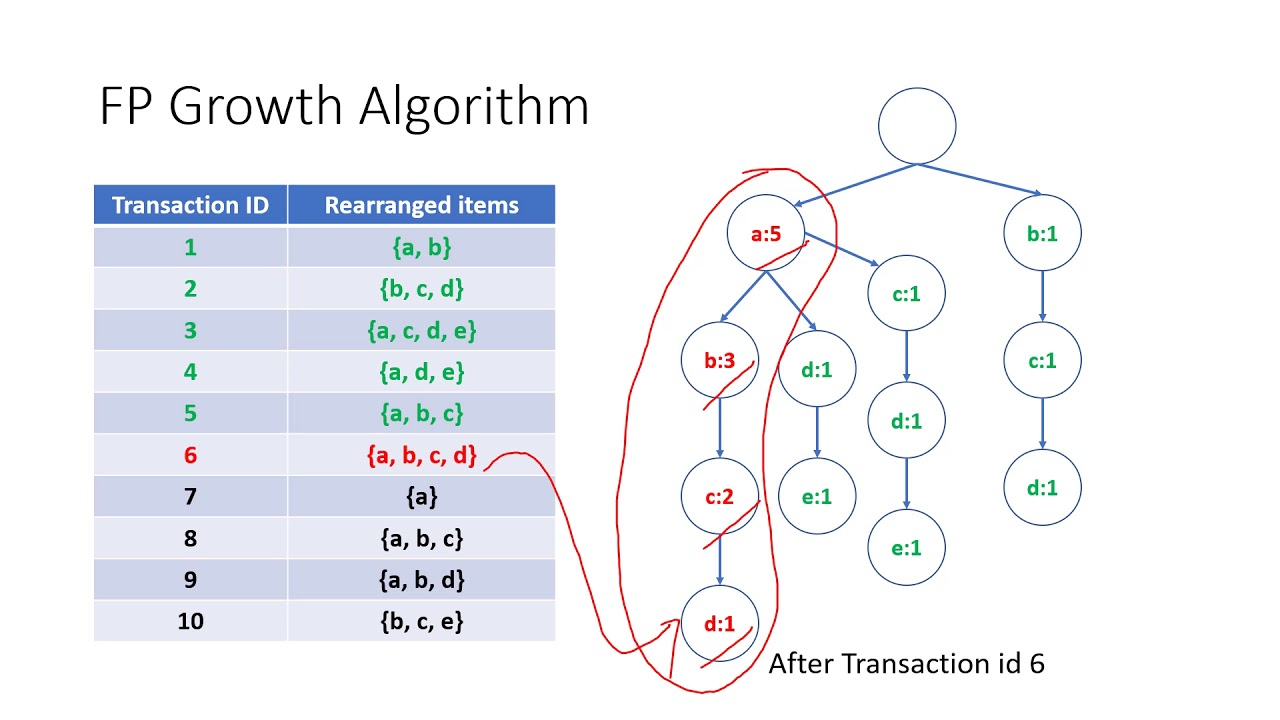

### Jak to działa?

FP-Growth unika tego, co spowalnia Apriori, czyli **tworzenia i sprawdzania ogromnej liczby kandydatów**. Zamiast tego **kompresuje wszystkie transakcje do jednego drzewa** (FP-tree) i szuka zestawów bezpośrednio w nim.

Jak powstaje drzewo (rysunek, 10 transakcji):

1. Zliczamy, jak często występuje każdy produkt, i odrzucamy te zbyt rzadkie.
2. W każdej transakcji **ustawiamy produkty od najczęstszych do najrzadszych** (kolumna *Rearranged items*).
3. Wstawiamy transakcje do drzewa po kolei. Transakcje zaczynające się tak samo **współdzielą początek ścieżki**, a licznik w węźle rośnie. Na rysunku, po transakcji 6, ścieżka a → b → c → d ma liczniki a:5, b:3, c:2, d:1. Znaczy to: 5 transakcji zawiera a, 3 z nich także b, 2 z nich także c i tylko 1 także d.
4. Aby znaleźć częste zestawy, dla każdego produktu bierzemy ścieżki, które do niego prowadzą, i odczytujemy z nich zestawy. Nie trzeba już wracać do pełnej bazy transakcji.

**Zaleta:** dane przeglądamy tylko dwa razy (liczenie produktów i budowa drzewa), więc zwykle jest szybszy od Apriori, szczególnie na dużych zbiorach. **Wada:** drzewo musi zmieścić się w pamięci, a sama idea jest trudniejsza do zrozumienia niż Apriori.

In [ ]:
fps = fpgrowth(koszykv2, min_support=0.06, use_colnames = True)
display(fps)

,support,itemsets
0,0.0975,(RED TOADSTOOL LED NIGHT LIGHT)
1,0.0850,(JUMBO BAG RED RETROSPOT)
2,0.0650,(SET/6 RED SPOTTY PAPER PLATES)
3,0.2600,(ROUND SNACK BOXES SET OF4 WOODLAND )
4,0.1700,(ROUND SNACK BOXES SET OF 4 FRUITS )
5,0.1225,(PLASTERS IN TIN CIRCUS PARADE )
6,0.1200,(PLASTERS IN TIN SPACEBOY)
7,0.0675,(PACK OF 20 NAPKINS PANTRY DESIGN)
8,0.0650,(PACK OF 20 NAPKINS RED APPLES)
9,0.1400,(WOODLAND CHARLOTTE BAG)


In [ ]:
association_rules(fps, metric="lift", min_threshold=2.5)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction,zhangs_metric
0,(ROUND SNACK BOXES SET OF 4 FRUITS ),(ROUND SNACK BOXES SET OF4 WOODLAND ),0.1700,0.2600,0.1400,0.823529,3.167421,0.095800,4.193333,0.824441
1,(ROUND SNACK BOXES SET OF4 WOODLAND ),(ROUND SNACK BOXES SET OF 4 FRUITS ),0.2600,0.1700,0.1400,0.538462,3.167421,0.095800,1.798333,0.924710
2,(PLASTERS IN TIN CIRCUS PARADE ),(PLASTERS IN TIN WOODLAND ANIMALS),0.1225,0.1475,0.0725,0.591837,4.012452,0.054431,2.088625,0.855585
3,(PLASTERS IN TIN WOODLAND ANIMALS),(PLASTERS IN TIN CIRCUS PARADE ),0.1475,0.1225,0.0725,0.491525,4.012452,0.054431,1.725750,0.880675
4,(PLASTERS IN TIN SPACEBOY),(PLASTERS IN TIN WOODLAND ANIMALS),0.1200,0.1475,0.0700,0.583333,3.954802,0.052300,2.046000,0.849026
5,(PLASTERS IN TIN WOODLAND ANIMALS),(PLASTERS IN TIN SPACEBOY),0.1475,0.1200,0.0700,0.474576,3.954802,0.052300,1.674839,0.876414
6,(RED RETROSPOT CHARLOTTE BAG),(WOODLAND CHARLOTTE BAG),0.0750,0.1400,0.0650,0.866667,6.190476,0.054500,6.450000,0.906445
7,(WOODLAND CHARLOTTE BAG),(RED RETROSPOT CHARLOTTE BAG),0.1400,0.0750,0.0650,0.464286,6.190476,0.054500,1.726667,0.974955
8,(ROUND SNACK BOXES SET OF4 WOODLAND ),(SPACEBOY LUNCH BOX ),0.2600,0.1150,0.0775,0.298077,2.591973,0.047600,1.260822,0.829991
9,(SPACEBOY LUNCH BOX ),(ROUND SNACK BOXES SET OF4 WOODLAND ),0.1150,0.2600,0.0775,0.673913,2.591973,0.047600,2.269333,0.694004


Porównanie 3 metod:

| **Cechy**            | **FP-Growth**                                                                 | **Apriori**                                                                    | **ECLAT**                                                                 |
|-----------------------|------------------------------------------------------------------------------|-------------------------------------------------------------------------------|---------------------------------------------------------------------------|
| **Prędkość**   | Szybszy, czas działania rośnie liniowo z liczbą zbiorów elementów.           | Wolniejszy, czas działania rośnie wykładniczo wraz ze wzrostem liczby zbiorów. | Szybszy niż Apriori, działa wydajnie przy mniejszych i gęstych zbiorach.  |
| **Pamięć**    | Mała, przechowuje skompresowaną wersję bazy danych (FP-tree).                | Duża, przechowuje wszystkie kandydaty generowane podczas łączenia (self-joining). | Średnia, przechowuje indeksy transakcji, co zmniejsza zużycie pamięci.    |
| **Kandydaci** | Nie generuje kandydatów, wykorzystuje strukturę FP-tree do wzrostu wzorców. | Generuje kandydatów przez iteracyjne łączenie (self-joining).                | Nie generuje kandydatów, wykorzystuje listy transakcji do znajdowania wzorców. |
| **Częste wzorce** | Osiągnięte poprzez eksplorację warunkowych FP-tree.                            | Wzorce wybierane z kandydatów o wsparciu wyższym niż `minsup`.               | Znajduje wzorce poprzez przecięcie list transakcji, spełniających `minsup`. |
| **Skany bazy danych** | Wymaga tylko dwóch pełnych skanów bazy danych.                                       | Wielokrotne skanowanie bazy danych przy każdej iteracji.                    | Wymaga jednego pełnego skanu do zbudowania list transakcji.              |
